
Обучение Random Forest...
Лучшие параметры: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}

Classification Report:
              precision    recall  f1-score   support

        high       0.81      0.54      0.64       383
         low       1.00      0.07      0.13        74
      medium       0.85      0.97      0.91      1493

    accuracy                           0.85      1950
   macro avg       0.89      0.52      0.56      1950
weighted avg       0.85      0.85      0.83      1950


Анализ важности признаков:


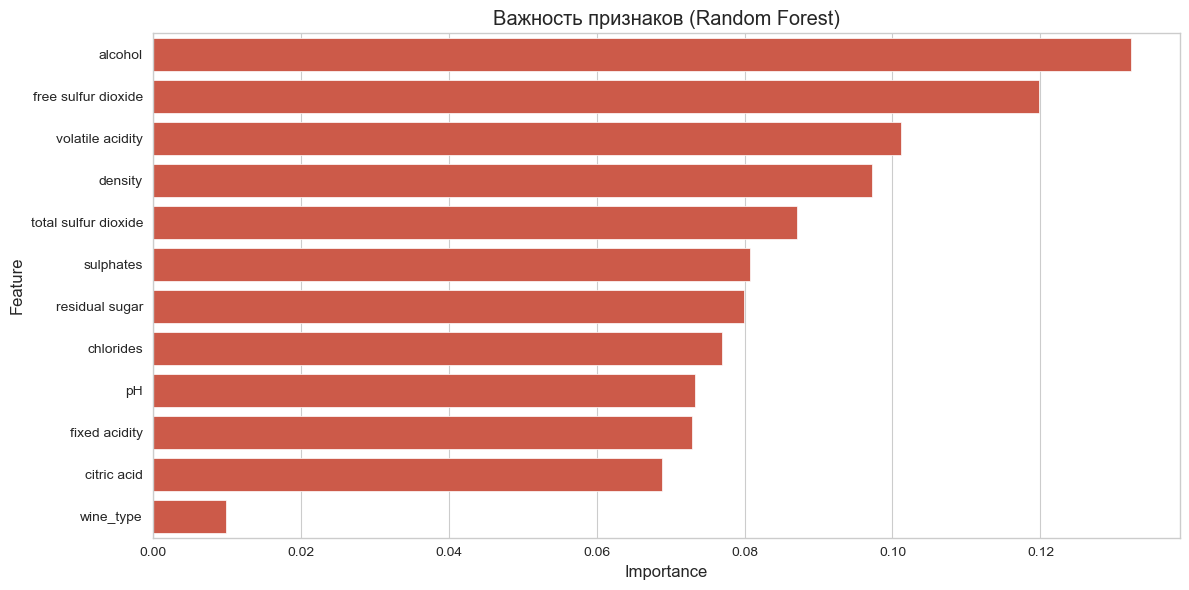

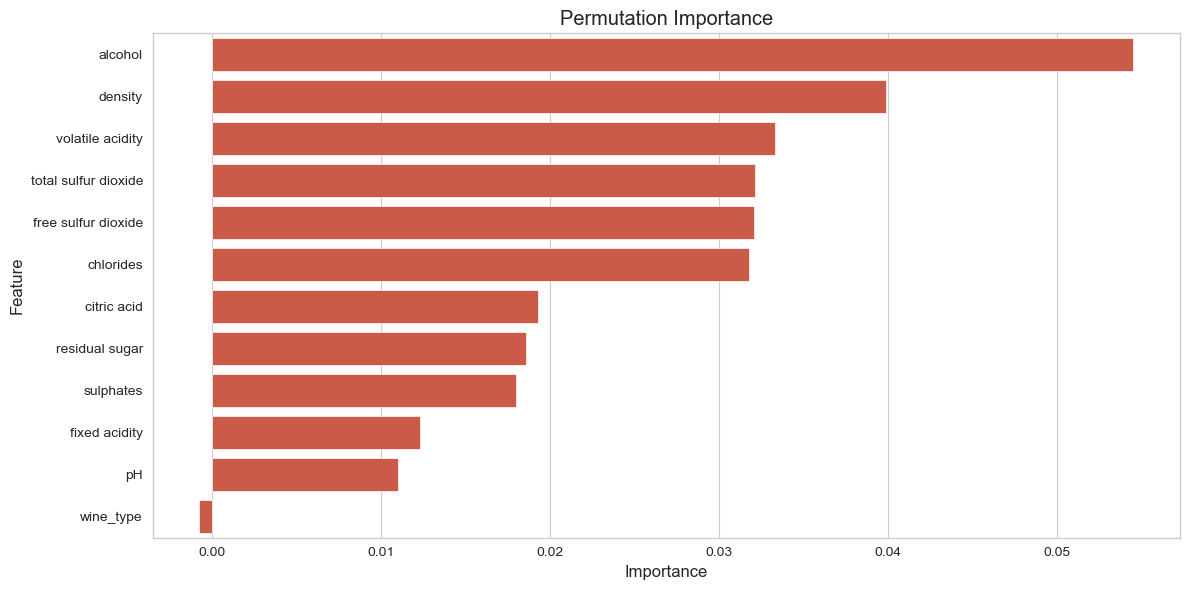


Расчет SHAP значений...


<Figure size 1200x600 with 0 Axes>

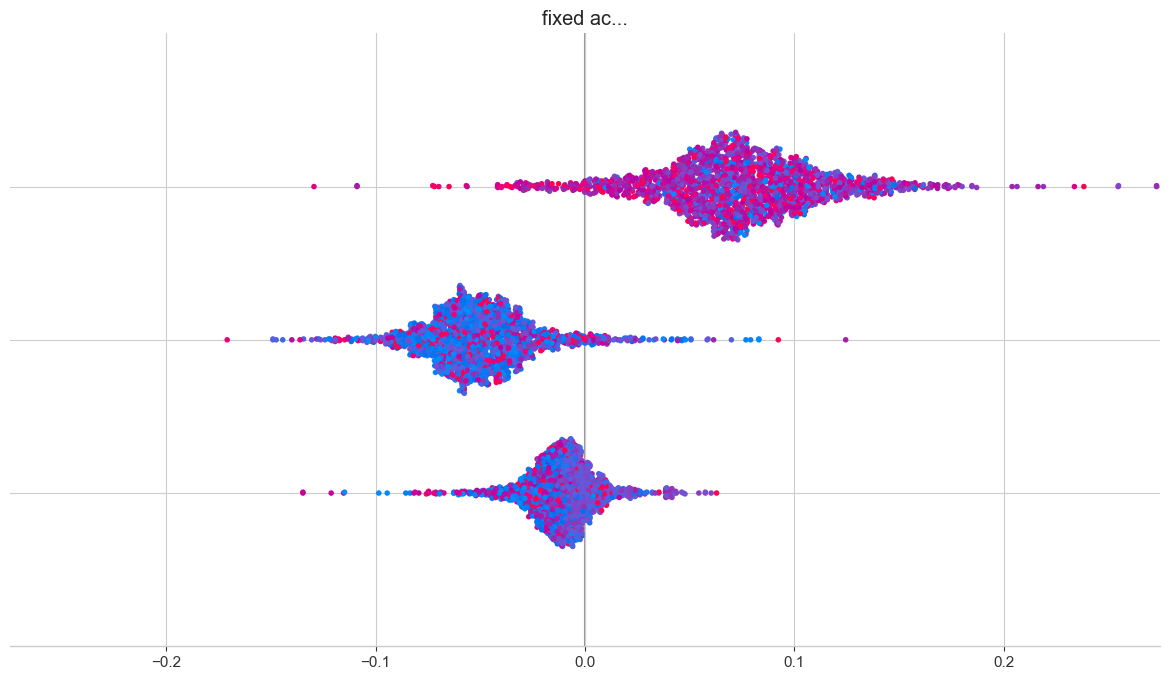

<Figure size 640x480 with 0 Axes>


Информация о модели:
Тип модели: RandomForestClassifier
Количество деревьев: 200
Используемые признаки: 12


In [1]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.inspection import permutation_importance
import shap
shap.initjs()  # Инициализация JS для визуализации SHAP

# Установка стилей
plt.style.use('ggplot')
sns.set_style("whitegrid")

# Загрузка данных
def load_data():
    red_wine = pd.read_csv('wine+quality/winequality-red.csv', sep=';')
    white_wine = pd.read_csv('wine+quality/winequality-white.csv', sep=';')
    
    red_wine['wine_type'] = 0  # 0 для красного вина
    white_wine['wine_type'] = 1  # 1 для белого вина
    
    data = pd.concat([red_wine, white_wine], ignore_index=True)
    data['quality_class'] = pd.cut(data['quality'], 
                                 bins=[0, 4, 6, 10],
                                 labels=['low', 'medium', 'high'])
    return data

# Подготовка данных
def prepare_data(data):
    X = data.drop(['quality', 'quality_class'], axis=1)
    y = data['quality_class']
    
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled, y_train, y_test, X.columns, le.classes_

# Обучение модели Random Forest
def train_random_forest(X_train, y_train):
    print("\nОбучение Random Forest...")
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10],
        'class_weight': ['balanced']
    }
    
    rf = RandomForestClassifier(random_state=42)
    grid = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    print(f"Лучшие параметры: {grid.best_params_}")
    return grid.best_estimator_

# Анализ важности признаков
def analyze_feature_importance(model, X_test, y_test, feature_names, class_names):
    print("\nАнализ важности признаков:")
    
    # 1. Встроенная важность
    importances = model.feature_importances_
    feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    feat_imp = feat_imp.sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x='Importance', y='Feature', data=feat_imp)
    plt.title("Важность признаков (Random Forest)")
    plt.tight_layout()
    plt.show()
    
    # 2. Permutation Importance
    perm_imp = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
    perm_imp_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': perm_imp.importances_mean
    }).sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x='Importance', y='Feature', data=perm_imp_df)
    plt.title("Permutation Importance")
    plt.tight_layout()
    plt.show()
    
    # 3. SHAP значения
    print("\nРасчет SHAP значений...")
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)
    
    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, X_test, feature_names=feature_names, class_names=class_names)
    plt.tight_layout()
    plt.show()
    
    return feat_imp, perm_imp_df

# Основной блок выполнения
if __name__ == "__main__":
    # Загрузка и подготовка данных
    wine_data = load_data()
    X_train, X_test, y_train, y_test, feature_names, class_names = prepare_data(wine_data)
    
    # Обучение Random Forest
    rf_model = train_random_forest(X_train, y_train)
    
    # Оценка модели
    y_pred = rf_model.predict(X_test)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names))
    
    # Анализ важности признаков
    feat_imp, perm_imp = analyze_feature_importance(
        rf_model, X_test, y_test, feature_names, class_names)
    
    # Вывод информации о модели
    print("\nИнформация о модели:")
    print(f"Тип модели: {type(rf_model).__name__}")
    print(f"Количество деревьев: {rf_model.n_estimators}")
    print(f"Используемые признаки: {rf_model.n_features_in_}")